# 03 · Combine trait features: first-step quickness, lateral agility, burst
**DS 5110 Big Data Systems — Final Project: Trench Play (OL and DL)**

**What this notebook does**
Turns 10 Hz Combine drill tracking into three movement traits for every OL and DL prospect:

| Trait | Per-attempt metrics (from tracking) | Drills used (see `config.TRAIT_DRILLS`) |
|---|---|---|
| **First-step quickness** | `t_1yd`, `t_2yd` = time from first movement to 1 / 2 yd away; `s03`, `s05` = speed 0.3 / 0.5 s after first movement | OL: pass-set drop, pull drills, 40 · DL: pass-rush, wave start, run-and-club, 40 |
| **Lateral agility** | at every direction **reversal**: `rev_time` (time spent below 70% of entry speed), `rev_brake` (peak braking into it), `rev_reacc` (peak re-acceleration out of it); `move_speed` (mean speed while moving) | OL: 5-yd wave slide-and-shuffle, pass-pro mirror · DL: wave lateral reaction, four-bag, body control · both: tracked shuttle / 3-cone |
| **Burst** | `acc_peak` = peak signed acceleration in the first 1.5 s; `s10` = speed at 1.0 s; `d10` = ground covered in the first 1.0 s | OL: pull drills, screen, 40 · DL: pass-rush, run-and-club, hoop, 40 |

Steps:
1. Frame-level kinematics with Spark window functions (smoothed speed, **signed** acceleration, displacement from the start point, reversal detection).
2. Attempt-level metrics → each player's **best attempt** per drill.
3. **Trait indices**: within each position group, every drill × metric is z-scored (oriented so higher = better) using **2023–24 players only** (the 2025 test class never informs the scaling). Each trait index = mean of the player's available z-scores.
4. Matching **stopwatch indices** from 10-yard split (first step), shuttle + 3-cone (lateral), broad + vertical + 40 (burst), and **size-adjusted** trait indices (residual after body weight).

**Inputs:** `processed/combine_tracking.parquet`, `processed/line_players.parquet`
**Outputs:** `processed/trait_attempts.parquet`, `processed/trait_drill_best.parquet`, `processed/trait_indices.parquet`, `outputs/tables/03_*.csv`, `outputs/figures/03_*.png`

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import config as C

spark = C.get_spark("03_traits")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
T0 = time.time()
players = spark.read.parquet(C.p("line_players.parquet"))
ct = spark.read.parquet(C.p("combine_tracking.parquet"))
used = sorted({d for g in C.TRAIT_DRILLS.values() for ds in g.values() for d in ds})
ct = ct.filter(F.col("drill_name").isin(used))
print(f"frames in trait drills: {ct.count():,}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/apps/software/standard/core/spark/4.2.0/python/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/26 21:36:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


frames in trait drills: 154,283


## 1. Frame-level kinematics
Within each attempt (`event_id`, ordered by time):
* `s_sm` = 3-frame centred mean of speed; `a_tan` = centred difference of `s_sm` (**signed**: + speeding up, − braking; the raw `a` column is an unsigned magnitude).
* **Onset** = first frame with `s_sm` > 0.5 yd/s; `t_rel` = seconds since onset; `disp` = straight-line distance from the onset position.
* **Reversal**: the path over the previous 0.4 s and the next 0.4 s both exceed 0.3 yd and point more than 120° apart. Consecutive flagged frames are one reversal, anchored at its slowest frame.

In [2]:
ONSET, K = 0.5, 4                     # onset speed (yd/s); look-back/look-ahead frames for reversals
w = Window.partitionBy("event_id").orderBy("ts")
w3 = w.rowsBetween(-1, 1)
k = (ct
     .withColumn("s_sm", F.avg("s").over(w3))
     .withColumn("dt2", F.lead(F.col("ts").cast("double")).over(w) - F.lag(F.col("ts").cast("double")).over(w))
     .withColumn("a_tan", (F.lead("s_sm").over(w) - F.lag("s_sm").over(w)) / F.col("dt2"))
     .withColumn("ux1", F.col("x") - F.lag("x", K).over(w)).withColumn("uy1", F.col("y") - F.lag("y", K).over(w))
     .withColumn("ux2", F.lead("x", K).over(w) - F.col("x")).withColumn("uy2", F.lead("y", K).over(w) - F.col("y"))
     .withColumn("n1", F.sqrt(F.col("ux1")**2 + F.col("uy1")**2)).withColumn("n2", F.sqrt(F.col("ux2")**2 + F.col("uy2")**2))
     .withColumn("cos12", (F.col("ux1") * F.col("ux2") + F.col("uy1") * F.col("uy2")) / (F.col("n1") * F.col("n2")))
     .withColumn("rev_flag", ((F.col("n1") > 0.3) & (F.col("n2") > 0.3) & (F.col("cos12") < -0.5)).cast("int")))
onset = (k.filter(F.col("s_sm") > ONSET).withColumn("r", F.row_number().over(w)).filter("r = 1")
          .select("event_id", F.col("t_sec").alias("t_on"), F.col("x").alias("x_on"), F.col("y").alias("y_on")))
k = (k.join(onset, "event_id", "inner")
      .withColumn("t_rel", F.round(F.col("t_sec") - F.col("t_on"), 2))
      .withColumn("disp", F.sqrt((F.col("x") - F.col("x_on"))**2 + (F.col("y") - F.col("y_on"))**2)))
# reversal apex = slowest frame within each run of flagged frames
wr = w.rowsBetween(-3, 3)
k = (k.withColumn("min_s_flag", F.min(F.when(F.col("rev_flag") == 1, F.col("s_sm"))).over(wr))
      .withColumn("apex", ((F.col("rev_flag") == 1) & (F.col("s_sm") == F.col("min_s_flag"))).cast("int")))
k = k.select("event_id", "nfl_id", "line_group", "draft_year", "drill_name", "attempt", "ts", "t_sec", "t_rel",
             "s_sm", "a_tan", "step_xy", "disp", "apex")
k.cache()
print(f"frames with kinematics: {k.count():,}; reversal apexes: {k.filter('apex = 1').count():,}")

frames with kinematics: 154,283; reversal apexes: 1,672


## 2. Attempt-level metrics
Reversal metrics use time-range windows around each apex (±1 s); an attempt's value is the median over its reversals.

In [3]:
# rangeBetween needs integer bounds, so time is ordered in tenths of a second (frames are 0.1 s apart)
k = k.withColumn("t_ds", F.round(F.col("t_sec") * 10).cast("long"))
wt = Window.partitionBy("event_id").orderBy("t_ds")
rv = (k.withColumn("entry_peak", F.max("s_sm").over(wt.rangeBetween(-10, 0)))
       .withColumn("rev_brake", F.min("a_tan").over(wt.rangeBetween(-6, 0)))
       .withColumn("rev_reacc", F.max("a_tan").over(wt.rangeBetween(0, 6))))
# time below 70% of the entry speed within ±1 s of the apex (frames × 0.1 s)
slow = (k.alias("f").join(rv.filter("apex = 1").select("event_id", F.col("t_sec").alias("t_apex"), "entry_peak",
                                                     "rev_brake", "rev_reacc").alias("a"), "event_id")
         .filter((F.col("f.t_sec") >= F.col("a.t_apex") - 1.0) & (F.col("f.t_sec") <= F.col("a.t_apex") + 1.0))
         .groupBy("event_id", "t_apex", "entry_peak", "rev_brake", "rev_reacc")
         .agg((F.sum((F.col("f.s_sm") < 0.7 * F.col("a.entry_peak")).cast("int")) * 0.1).alias("rev_time"))
         .filter(F.col("entry_peak") > 1.0))          # ignore "reversals" from a near standstill
rev_att = (slow.groupBy("event_id").agg(F.expr("percentile_approx(rev_time, 0.5)").alias("rev_time"),
                                         F.expr("percentile_approx(rev_brake, 0.5)").alias("rev_brake"),
                                         F.expr("percentile_approx(rev_reacc, 0.5)").alias("rev_reacc"),
                                         F.count("*").alias("n_reversals")))

def speed_at(t):
    return F.max(F.when((F.col("t_rel") >= t - 0.05) & (F.col("t_rel") < t + 0.05), F.col("s_sm")))

att = (k.groupBy("event_id", "nfl_id", "line_group", "draft_year", "drill_name", "attempt")
       .agg(F.min(F.when((F.col("t_rel") >= 0) & (F.col("disp") >= 1.0), F.col("t_rel"))).alias("t_1yd"),
            F.min(F.when((F.col("t_rel") >= 0) & (F.col("disp") >= 2.0), F.col("t_rel"))).alias("t_2yd"),
            speed_at(0.3).alias("s03"), speed_at(0.5).alias("s05"), speed_at(1.0).alias("s10"),
            F.sum(F.when((F.col("t_rel") > 0) & (F.col("t_rel") <= 1.0), F.col("step_xy"))).alias("d10"),
            F.max(F.when((F.col("t_rel") >= 0) & (F.col("t_rel") <= 1.5), F.col("a_tan"))).alias("acc_peak"),
            F.avg(F.when(F.col("s_sm") > ONSET, F.col("s_sm"))).alias("move_speed"),
            F.count("*").alias("n_frames"))
       .join(rev_att, "event_id", "left"))
att.write.mode("overwrite").parquet(C.p("trait_attempts.parquet"))
att = spark.read.parquet(C.p("trait_attempts.parquet"))
summ = (att.groupBy("line_group", "drill_name").agg(F.count("*").alias("attempts"), F.countDistinct("nfl_id").alias("players"),
        *[F.round(F.expr(f"percentile_approx({m}, 0.5)"), 2).alias(m) for m in
          ["t_1yd", "s05", "acc_peak", "s10", "rev_time", "rev_reacc", "move_speed", "n_reversals"]])
        .orderBy("line_group", "drill_name").toPandas())
summ.to_csv(C.TABLE_DIR / "03_attempt_metric_medians.csv", index=False)
summ

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,line_group,drill_name,attempts,players,t_1yd,s05,acc_peak,s10,rev_time,rev_reacc,move_speed,n_reversals
0,DL,BODY_CONTROL_DRILL,113,111,0.6,2.26,3.72,3.05,0.9,5.94,4.51,1.0
1,DL,FORTY_YARD_DASH,177,93,0.6,2.77,5.22,5.33,NaN,NaN,7.77,NaN
2,DL,FOUR_BAG_AGILITY_DRILL,112,112,0.7,1.68,3.54,1.60,0.6,3.93,2.90,1.0
3,DL,FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION,112,112,0.8,1.75,3.73,3.18,0.9,5.64,3.55,3.0
4,DL,PASS_RUSH_DRILL,225,118,0.7,2.41,4.24,3.88,NaN,NaN,5.10,NaN
5,DL,RUN_AND_CLUB_DRILL,113,112,0.6,2.56,4.33,3.96,0.9,5.55,3.62,1.0
6,DL,RUN_THE_HOOP_DRILL,119,109,0.6,2.35,3.88,3.47,NaN,NaN,3.54,NaN
7,DL,SHORT_SHUTTLE,44,38,0.6,2.28,3.42,3.03,0.7,6.61,2.95,2.0
8,DL,THREE_CONE_DRILL,60,45,0.6,2.19,3.28,2.45,0.7,4.62,2.91,2.0
9,OL,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,120,120,1.0,1.16,2.39,1.06,0.8,4.48,2.90,3.0


## 3. Best attempt per player × drill × metric
Best = minimum for "lower is better" metrics (`t_1yd`, `t_2yd`, `rev_time`, `rev_brake`), maximum otherwise. Only the drill × metric pairs assigned to a trait in `config.py` are kept.

In [4]:
metric_sign = {m: s for tr in C.TRAIT_METRICS.values() for m, s in tr.items()}
aggs = [(F.min(m) if s < 0 else F.max(m)).alias(m) for m, s in metric_sign.items()]
best = att.groupBy("nfl_id", "line_group", "draft_year", "drill_name").agg(*aggs, F.count("*").alias("attempts"))
best.write.mode("overwrite").parquet(C.p("trait_drill_best.parquet"))

rows = []
for grp, traits in C.TRAIT_DRILLS.items():
    for trait, drills in traits.items():
        for d in drills:
            for m, s in C.TRAIT_METRICS[trait].items():
                rows.append((grp, trait, d, m, s))
comp = (spark.createDataFrame(rows, "line_group string, trait string, drill_name string, metric string, sign int")
             .withColumn("component", F.concat_ws("|", "trait", "drill_name", "metric")))
best = spark.read.parquet(C.p("trait_drill_best.parquet"))
metrics = list(metric_sign)
unpivot = "stack({}, {}) as (metric, value)".format(len(metrics), ", ".join(f"'{m}', cast({m} as double)" for m in metrics))
long = (best.select("nfl_id", "line_group", "draft_year", "drill_name", F.expr(unpivot))       # wide → long, in Spark
            .filter(F.col("value").isNotNull())
            .join(F.broadcast(comp), ["line_group", "drill_name", "metric"]))
print("trait components with data:", long.select("component").distinct().count())

trait components with data: 84


## 4. Trait indices (z-scores fitted on 2023–24 players)
A component needs values for at least 60% of its group's players to count. Each player's trait index is the mean of his available oriented z-scores, so a prospect who skipped a drill is still scored from the others.

In [5]:
is_fit = F.col("draft_year") != C.TEST_DRAFT_CLASS
n_group = best.filter(is_fit).groupBy("line_group").agg(F.countDistinct("nfl_id").alias("n_group"))
stats = (long.filter(is_fit).groupBy("line_group", "component")
             .agg(F.avg("value").alias("mean"), F.stddev_samp("value").alias("std"), F.count("value").alias("count"))
             .join(n_group, "line_group").withColumn("coverage", F.col("count") / F.col("n_group")))
keep = stats.filter(F.col("coverage") >= 0.6).cache()
print(f"components kept: {keep.count()} of {stats.count()}")
clip3 = lambda c: F.when(c.isNotNull(), F.greatest(F.lit(-3.0), F.least(F.lit(3.0), c)))   # winsorize; keep missing as missing
z = (long.join(F.broadcast(keep.select("line_group", "component", "mean", "std")), ["line_group", "component"])
         .withColumn("z", clip3(F.col("sign") * (F.col("value") - F.col("mean")) / F.col("std"))))
idx = z.groupBy("nfl_id", "line_group").pivot("trait", C.TRAITS).agg(F.avg("z").alias("trk"), F.count("z").alias("n"))
for t in C.TRAITS:
    idx = (idx.withColumnRenamed(f"{t}_trk", f"trk_{t}")
              .withColumn(f"n_{t}", F.when(F.col(f"{t}_n") > 0, F.col(f"{t}_n").cast("double"))).drop(f"{t}_n"))
keep_pd = keep.orderBy("line_group", "component").toPandas()
keep_pd.to_csv(C.TABLE_DIR / "03_trait_components.csv", index=False)
keep_pd.pivot(index="component", columns="line_group", values="coverage").round(2).head(40)

components kept: 77 of 99


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


line_group,DL,OL
component,,
burst|FORTY_YARD_DASH|acc_peak,0.86,0.81
burst|FORTY_YARD_DASH|d10,0.86,0.81
burst|FORTY_YARD_DASH|s10,0.86,0.81
burst|OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT|acc_peak,NaN,0.72
burst|OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT|d10,NaN,0.72
burst|OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT|s10,NaN,0.72
burst|OL_PULL_DRILL_FOLD_BLOCK_RIGHT|acc_peak,NaN,0.98
burst|OL_PULL_DRILL_FOLD_BLOCK_RIGHT|d10,NaN,0.98
burst|OL_PULL_DRILL_FOLD_BLOCK_RIGHT|s10,NaN,0.98


## 5. Stopwatch indices and size-adjusted trait indices
* **Stopwatch indices**: the same z-score recipe applied to the traditional drill each trait is usually judged by.
* **Size-adjusted** (`adj_*`): the residual of each tracking trait index after a linear fit on body weight within the position group (fitted on 2023–24 players). It separates "moves well for his size" from "is light".

In [6]:
sw_cols = sorted({c for parts in C.TRAD_TRAITS.values() for c in parts})
pl = players.select("nfl_id", "line_group", "draft_year", "nfl_position", "combine_weight", "combine_height", "arm_length", *sw_cols)
ref = pl.filter(is_fit).groupBy("line_group").agg(*[F.avg(c).alias(f"{c}__mu") for c in sw_cols],
                                                  *[F.stddev_samp(c).alias(f"{c}__sd") for c in sw_cols])
pl = pl.join(F.broadcast(ref), "line_group")
for trait, parts in C.TRAD_TRAITS.items():
    zs = [clip3(F.lit(float(sgn)) * (F.col(c) - F.col(f"{c}__mu")) / F.col(f"{c}__sd")) for c, sgn in parts.items()]
    n_ok = sum(F.when(zz.isNotNull(), 1).otherwise(0) for zz in zs)
    tot = sum(F.coalesce(zz, F.lit(0.0)) for zz in zs)
    pl = pl.withColumn(f"sw_{trait}", F.when(n_ok > 0, tot / n_ok))             # mean of the available drills
out = pl.join(idx, ["nfl_id", "line_group"], "left")
# size adjustment: least-squares line trk ~ weight per group on 2023-24 players, residual for everyone
fit_aggs = []
for t in C.TRAITS:
    ok = is_fit & F.col(f"trk_{t}").isNotNull() & F.col("combine_weight").isNotNull()
    wv, tv = F.when(ok, F.col("combine_weight")), F.when(ok, F.col(f"trk_{t}"))
    fit_aggs += [F.covar_samp(wv, tv).alias(f"{t}__cov"), F.var_samp(wv).alias(f"{t}__var"),
                 F.avg(wv).alias(f"{t}__wmu"), F.avg(tv).alias(f"{t}__tmu")]
out = out.join(F.broadcast(out.groupBy("line_group").agg(*fit_aggs)), "line_group")
for t in C.TRAITS:
    b1 = F.col(f"{t}__cov") / F.col(f"{t}__var"); b0 = F.col(f"{t}__tmu") - b1 * F.col(f"{t}__wmu")
    out = out.withColumn(f"adj_{t}", F.col(f"trk_{t}") - (b0 + b1 * F.col("combine_weight")))
keep_cols = (["nfl_id", "line_group"] + [f"{p}_{t}" for p in ("trk", "sw", "adj") for t in C.TRAITS] +
             [f"n_{t}" for t in C.TRAITS])
out.select("nfl_id", "line_group", *[F.col(c).cast("double") for c in keep_cols[2:]]) \
   .write.mode("overwrite").parquet(C.p("trait_indices.parquet"))
ti = spark.read.parquet(C.p("trait_indices.parquet"))
cov = (ti.groupBy("line_group").agg(*[F.round(F.avg(F.col(c).isNotNull().cast("double")), 2).alias(c)
                                      for c in [f"trk_{t}" for t in C.TRAITS] + [f"sw_{t}" for t in C.TRAITS]])
         .orderBy("line_group").toPandas())
cov.to_csv(C.TABLE_DIR / "03_index_coverage.csv", index=False)
print("share of players with each index:"); cov

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


share of players with each index:


,line_group,trk_first_step,trk_lateral,trk_burst,sw_first_step,sw_lateral,sw_burst
0,DL,1.0,0.97,1.0,0.80,0.43,0.92
1,OL,1.0,1.00,1.0,0.79,0.60,0.90


## 6. How the traits relate to each other, to size and to the stopwatch
Spearman correlations within each position group. High tracking-vs-stopwatch correlation means tracking re-measures the stopwatch; low means it adds a different view.

In [7]:
tw = ti.join(players.select("nfl_id", "combine_weight", "nfl_position"), "nfl_id")
parts = []
for t in C.TRAITS:
    for other, lab in [(f"sw_{t}", "same-trait stopwatch index"), ("combine_weight", "body weight")] + \
                      [(f"trk_{o}", f"tracking {o}") for o in C.TRAITS if o != t]:
        parts.append(C.spearman(tw, f"trk_{t}", other, by=["line_group"])
                      .select(F.col("line_group").alias("group"), F.lit(t).alias("trait"), F.lit(lab).alias("vs"), "n",
                              F.round("spearman", 2).alias("spearman")))
rel_sdf = parts[0]
for p_ in parts[1:]:
    rel_sdf = rel_sdf.unionByName(p_)
rel = rel_sdf.orderBy("group", "trait", "vs").toPandas()
rel.to_csv(C.TABLE_DIR / "03_trait_relationships.csv", index=False)
out = tw.toPandas()          # 239 players: input for the two figures below only
rel.pivot_table(index=["group", "trait"], columns="vs", values="spearman")

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


vs                body weight  same-trait stopwatch index  tracking burst  \
group trait                                                                 
DL    burst             -0.45                        0.37             NaN   
      first_step        -0.15                        0.23            0.64   
      lateral           -0.38                        0.41            0.46   
OL    burst             -0.07                        0.29             NaN   
      first_step        -0.05                        0.27            0.61   
      lateral           -0.20                        0.32           -0.05   

vs                tracking first_step  tracking lateral  
group trait                                              
DL    burst                      0.64              0.46  
      first_step                  NaN              0.20  
      lateral                    0.20               NaN  
OL    burst                      0.61             -0.05  
      first_step                  NaN              0.00  
      lateral                    0.00               NaN

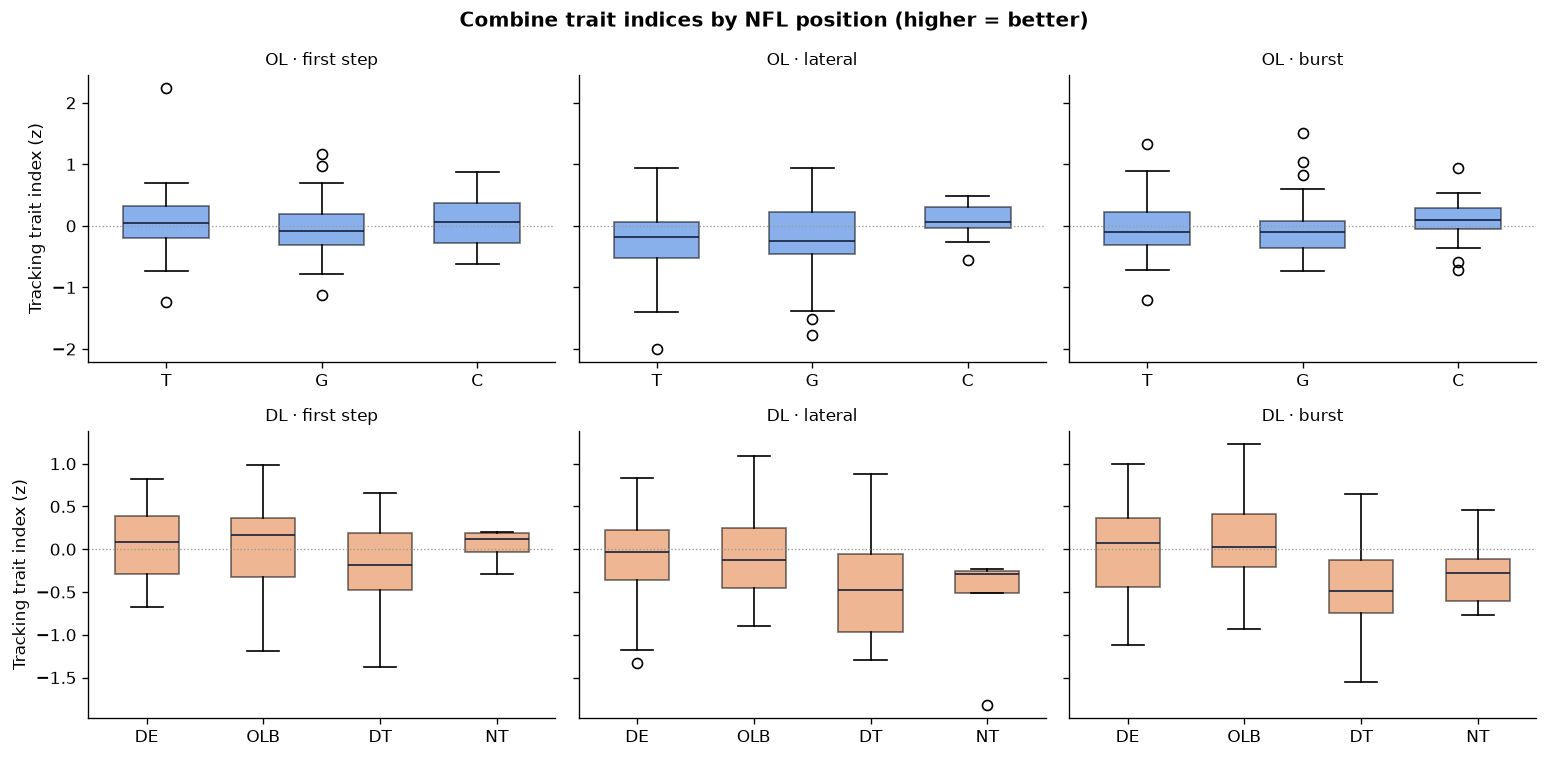

In [8]:
# Figure: trait index distributions by NFL position within each group
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharey="row")
pos_order = {"OL": ["T", "G", "C"], "DL": ["DE", "OLB", "DT", "NT"]}
for r, g in enumerate(C.GROUPS):
    d = out[out.line_group == g]
    for c, t in enumerate(C.TRAITS):
        ax = axes[r, c]
        cats = [p for p in pos_order[g] if (d.nfl_position == p).sum() >= 3]
        data = [d.loc[d.nfl_position == p, f"trk_{t}"].dropna() for p in cats]
        bp_ = ax.boxplot(data, patch_artist=True, widths=.55, medianprops={"color": "#14213D"})
        ax.set_xticks(range(1, len(cats) + 1), cats)   # works on old and new matplotlib
        for b in bp_["boxes"]:
            b.set_facecolor("#2a6fdb" if g == "OL" else "#e07b39"); b.set_alpha(.55)
        ax.axhline(0, color="#999", lw=.8, ls=":")
        ax.set_title(f"{g} · {t.replace('_', ' ')}", fontsize=10)
    axes[r, 0].set_ylabel("Tracking trait index (z)")
fig.suptitle("Combine trait indices by NFL position (higher = better)", fontweight="bold")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "03_trait_indices_by_position.png", bbox_inches="tight"); plt.show()

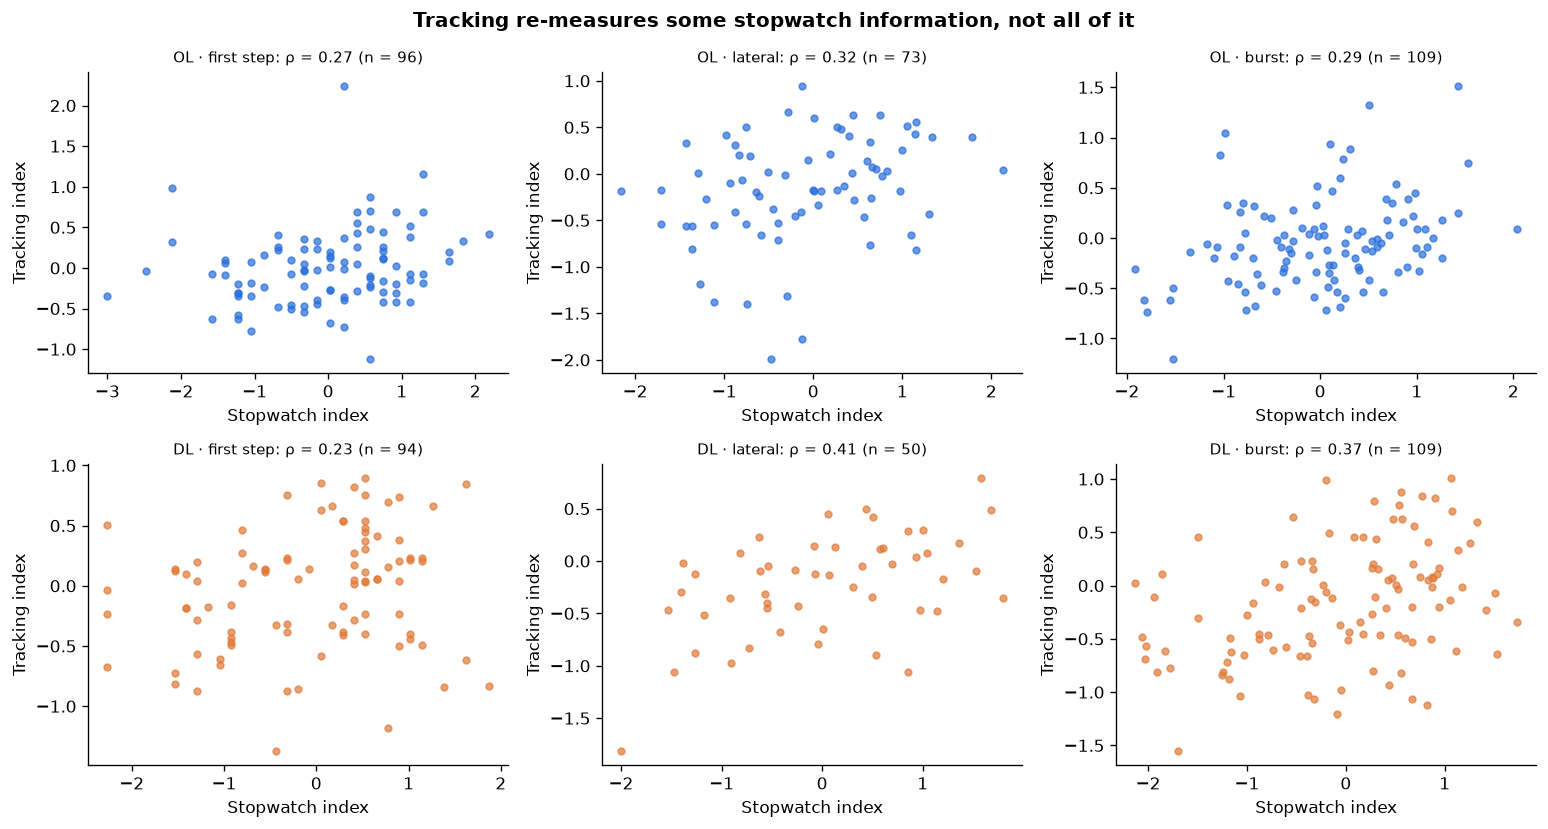

done in 33 s


In [9]:
# Figure: tracking vs stopwatch index per trait (OL and DL)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for r, g in enumerate(C.GROUPS):
    d = out[out.line_group == g]
    for c, t in enumerate(C.TRAITS):
        ax = axes[r, c]; dd = d[[f"sw_{t}", f"trk_{t}"]].dropna()
        ax.scatter(dd[f"sw_{t}"], dd[f"trk_{t}"], s=16, alpha=.7, color="#2a6fdb" if g == "OL" else "#e07b39")
        rho = rel[(rel.group == g) & (rel.trait == t) & (rel.vs == "same-trait stopwatch index")].spearman.iloc[0]
        ax.set_title(f"{g} · {t.replace('_', ' ')}: ρ = {rho:.2f} (n = {len(dd)})", fontsize=9)
        ax.set_xlabel("Stopwatch index"); ax.set_ylabel("Tracking index")
fig.suptitle("Tracking re-measures some stopwatch information, not all of it", fontweight="bold")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "03_tracking_vs_stopwatch.png", bbox_inches="tight"); plt.show()
print(f"done in {time.time() - T0:,.0f} s")